# Graph Analytics: Graph Traversal (BFS/DFS) and DBSCAN Clustering
**Course:** Query Design & Analysis  
**Dataset:** SNAP *ego-Facebook* network (McAuley & Leskovec, 2014): 4,039 anonymised Facebook users (nodes) and 88,234 friendships (undirected edges).  
**Source:** https://snap.stanford.edu/data/ego-Facebook.html

This notebook supports the written review. It covers:
1. Loading the graph and its basic properties
2. **Graph traversal**: BFS (hop distances, BFS tree, average path length, diameter) and DFS (connected components)
3. **Clustering**: DBSCAN on a structural (Jaccard) distance, choosing `eps` with a k-distance plot, and evaluating with modularity
4. Treating DBSCAN noise points as bridge or anomaly candidates

In [1]:
import gzip, os, time, urllib.request
from collections import Counter, deque

import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from networkx.algorithms.community import modularity, louvain_communities

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("networkx", nx.__version__)

networkx 3.7


## 1. Load the dataset

In [2]:
URL = "https://snap.stanford.edu/data/facebook_combined.txt.gz"
FILE = "facebook_combined.txt.gz"
if not os.path.exists(FILE):
    urllib.request.urlretrieve(URL, FILE)

with gzip.open(FILE, "rt") as f:
    G = nx.read_edgelist(f, nodetype=int)

deg = dict(G.degree())
summary = {
    "nodes": G.number_of_nodes(),
    "edges": G.number_of_edges(),
    "density": round(nx.density(G), 5),
    "average degree": round(np.mean(list(deg.values())), 2),
    "max degree (node)": f"{max(deg.values())} (node {max(deg, key=deg.get)})",
    "average clustering coefficient": round(nx.average_clustering(G), 3),
}
pd.Series(summary)

nodes                                        4039
edges                                       88234
density                                   0.01082
average degree                              43.69
max degree (node)                 1045 (node 107)
average clustering coefficient              0.606
dtype: object

## 2. Graph traversal
### 2.1 Breadth-first search, written by hand
BFS visits the graph one layer at a time. It uses a FIFO queue, so every node at distance *d* is visited before any node at distance *d+1*. That means BFS finds shortest paths (by hop count) in an unweighted graph in **O(V + E)** time.

In [3]:
def bfs(graph, source):
    """Return hop distance and BFS-tree parent for every node reachable from source."""
    dist, parent = {source: 0}, {source: None}
    queue = deque([source])
    while queue:
        u = queue.popleft()                 # FIFO -> level-by-level
        for v in graph.neighbors(u):
            if v not in dist:               # first visit = shortest hop distance
                dist[v] = dist[u] + 1
                parent[v] = u
                queue.append(v)
    return dist, parent

def path_to(parent, target):
    path = []
    while target is not None:
        path.append(target)
        target = parent[target]
    return path[::-1]

hub = max(deg, key=deg.get)          # most-connected user (node 107)
t0 = time.perf_counter()
dist, parent = bfs(G, hub)
print(f"BFS from node {hub} reached {len(dist)} nodes in {time.perf_counter()-t0:.4f}s")

# check against the networkx implementation
assert dist == nx.single_source_shortest_path_length(G, hub)
print("Matches networkx.single_source_shortest_path_length")

levels = Counter(dist.values())
pd.DataFrame({"hops": sorted(levels), "users reached": [levels[k] for k in sorted(levels)]}).T

BFS from node 107 reached 4039 nodes in 0.0070s
Matches networkx.single_source_shortest_path_length


,0,1,2,3,4,5
hops,0,1,2,3,4,5
users reached,1,1045,1641,1093,117,142


In [4]:
print("Shortest path 0 -> 4038:", path_to(bfs(G, 0)[1], 4038))
print("networkx check          :", nx.shortest_path(G, 0, 4038))

Shortest path 0 -> 4038: [0, 34, 414, 594, 3980, 4038]
networkx check          : [0, 34, 414, 594, 3980, 4038]


### 2.2 Average path length and diameter (BFS from every node: all-pairs BFS)

In [5]:
t0 = time.perf_counter()
ecc, total, pairs = {}, 0, 0
hop_hist = Counter()
for s in G:
    d = nx.single_source_shortest_path_length(G, s)
    ecc[s] = max(d.values())
    hop_hist.update(d.values())
    total += sum(d.values()); pairs += len(d) - 1
print(f"All-pairs BFS ({G.number_of_nodes()} traversals) took {time.perf_counter()-t0:.1f}s")
print("Average shortest path length:", round(total / pairs, 3))
print("Diameter:", max(ecc.values()), "| Radius:", min(ecc.values()))
del hop_hist[0]
hop_share = {k: v / pairs for k, v in sorted(hop_hist.items())}
print("Share of pairs within 4 hops: {:.1%}".format(sum(v for k, v in hop_share.items() if k <= 4)))

All-pairs BFS (4039 traversals) took 21.5s
Average shortest path length: 3.693
Diameter: 8 | Radius: 4
Share of pairs within 4 hops: 78.1%


### 2.3 Depth-first search: connected components
DFS uses a stack (LIFO) and follows one branch as deep as possible before it backtracks. It is the usual tool for connectivity, cycle detection and topological sorting (Tarjan, 1972).

In [6]:
def dfs_components(graph):
    seen, comps = set(), []
    for start in graph:
        if start in seen:
            continue
        stack, comp = [start], []
        seen.add(start)
        while stack:
            u = stack.pop()                  # LIFO -> go deep first
            comp.append(u)
            for v in graph.neighbors(u):
                if v not in seen:
                    seen.add(v); stack.append(v)
        comps.append(comp)
    return comps

comps = dfs_components(G)
print("Connected components:", len(comps), "| largest:", max(map(len, comps)))
print("networkx agrees:", nx.number_connected_components(G) == len(comps))

Connected components: 1 | largest: 4039
networkx agrees: True


### 2.4 Traversal figure

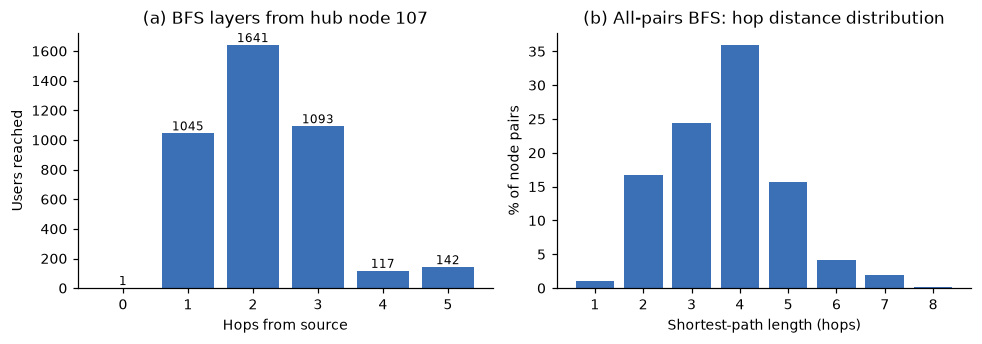

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ks = sorted(levels)
ax[0].bar(ks, [levels[k] for k in ks], color="#3B6FB6")
for k in ks:
    ax[0].text(k, levels[k], levels[k], ha="center", va="bottom", fontsize=8)
ax[0].set(title=f"(a) BFS layers from hub node {hub}", xlabel="Hops from source", ylabel="Users reached")

hk = list(hop_share)
ax[1].bar(hk, [hop_share[k]*100 for k in hk], color="#3B6FB6")
ax[1].set(title="(b) All-pairs BFS: hop distance distribution", xlabel="Shortest-path length (hops)", ylabel="% of node pairs")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("fig_traversal.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Clustering with DBSCAN
DBSCAN (Density-Based Spatial Clustering of Applications with Noise) needs two settings, `eps` (neighbourhood radius) and `min_samples` (minimum neighbours for a core point). Points are labelled as:
* **core**: has at least `min_samples` points within `eps`
* **border**: within `eps` of a core point, but not a core point itself
* **noise (-1)**: neither of the above

Graph nodes have no coordinates, so I give DBSCAN a **structural distance** instead: `1 - Jaccard similarity` of the closed neighbourhoods N[u] ∪ {u}. Two users are "close" when they share most of their friends. This is the same idea behind the SCAN graph-clustering algorithm (Xu et al., 2007).

In [8]:
nodes = np.array(list(G.nodes()))
idx = {n: i for i, n in enumerate(nodes)}
r, c = [], []
for n in nodes:
    for m in list(G.neighbors(n)) + [n]:      # closed neighbourhood
        r.append(idx[n]); c.append(idx[m])
A = sp.csr_matrix((np.ones(len(r)), (r, c)), shape=(len(nodes), len(nodes)))

inter = (A @ A.T).toarray()                    # |N[u] ∩ N[v]|
size = np.asarray(A.sum(axis=1)).ravel()       # |N[u]|
D = 1 - inter / (size[:, None] + size[None, :] - inter)   # Jaccard distance
print("Distance matrix:", D.shape, "| memory: %.0f MB" % (D.nbytes / 1e6))

Distance matrix: (4039, 4039) | memory: 131 MB


### 3.1 Choosing `eps` with a k-distance plot

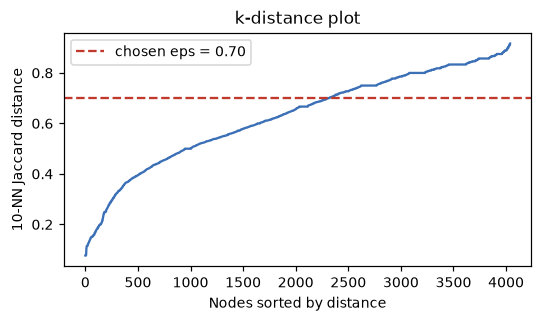

In [9]:
MIN_SAMPLES = 10
kdist = np.sort(np.sort(D, axis=1)[:, MIN_SAMPLES])
plt.figure(figsize=(5, 3))
plt.plot(kdist, color="#3B6FB6")
plt.axhline(0.70, ls="--", color="#C0392B", label="chosen eps = 0.70")
plt.xlabel("Nodes sorted by distance"); plt.ylabel(f"{MIN_SAMPLES}-NN Jaccard distance")
plt.title("k-distance plot"); plt.legend(); plt.tight_layout(); plt.show()

### 3.2 Parameter sensitivity

In [10]:
def evaluate(labels):
    k = labels.max() + 1
    clusters = [set(nodes[labels == i]) for i in range(k)]
    noise = set(nodes[labels == -1])
    Q = modularity(G, clusters + [{n} for n in noise])   # noise = singletons
    return k, len(noise), Q

rows = []
for eps in [0.5, 0.6, 0.7, 0.8]:
    for ms in [5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms, metric="precomputed").fit_predict(D)
        k, nn, Q = evaluate(lab)
        rows.append({"eps": eps, "min_samples": ms, "clusters": k,
                     "noise nodes": nn, "noise %": round(100*nn/len(nodes), 1), "modularity Q": round(Q, 3)})
sens = pd.DataFrame(rows); sens

,eps,min_samples,clusters,noise nodes,noise %,modularity Q
0,0.5,5,84,2005,49.6,0.466
1,0.5,10,48,2471,61.2,0.424
2,0.6,5,91,1325,32.8,0.640
3,0.6,10,54,1750,43.3,0.609
4,0.7,5,79,636,15.7,0.700
5,0.7,10,50,1097,27.2,0.689
6,0.8,5,13,67,1.7,0.490
7,0.8,10,17,177,4.4,0.589


### 3.3 Final model

In [11]:
EPS = 0.70
t0 = time.perf_counter()
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, metric="precomputed").fit(D)
labels = db.labels_
print(f"DBSCAN fit in {time.perf_counter()-t0:.2f}s")
k, n_noise, Q = evaluate(labels)
core = np.zeros(len(nodes), bool); core[db.core_sample_indices_] = True
print(f"clusters={k}  core={core.sum()}  border={(~core & (labels>=0)).sum()}  noise={n_noise} ({n_noise/len(nodes):.1%})")
print(f"Modularity (noise as singletons): {Q:.3f}")

# baseline: Louvain community detection (it puts every node in a community)
louv = louvain_communities(G, seed=42)
print(f"Louvain baseline: {len(louv)} communities, Q = {modularity(G, louv):.3f}")
print("Largest DBSCAN clusters:", sorted(Counter(labels[labels>=0]).values(), reverse=True)[:8])

DBSCAN fit in 0.04s
clusters=50  core=2413  border=529  noise=1097 (27.2%)
Modularity (noise as singletons): 0.689


Louvain baseline: 16 communities, Q = 0.835
Largest DBSCAN clusters: [464, 294, 286, 215, 197, 150, 119, 117]


### 3.4 Who are the noise points? (bridges and anomaly candidates)

In [12]:
bc = nx.betweenness_centrality(G, k=500, seed=1)       # sampled betweenness
lcc = nx.clustering(G)
prof = pd.DataFrame({
    "group": np.where(labels == -1, "noise", "clustered"),
    "degree": [deg[n] for n in nodes],
    "local clustering": [lcc[n] for n in nodes],
    "betweenness (x1e3)": [bc[n]*1e3 for n in nodes],
})
print(prof.groupby("group").mean().round(3))
top_bc = sorted(bc, key=bc.get, reverse=True)[:10]
print("Top-10 betweenness nodes labelled noise:", sum(labels[idx[n]] == -1 for n in top_bc), "/ 10")

           degree  local clustering  betweenness (x1e3)
group                                                  
clustered  54.770             0.605               0.407
noise      13.979             0.606               1.368
Top-10 betweenness nodes labelled noise: 5 / 10


### 3.5 Clustering figure

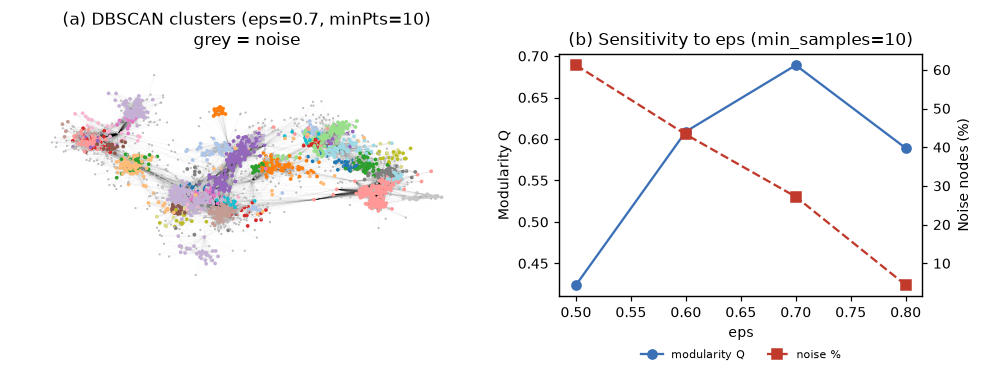

In [13]:
pos = nx.spring_layout(G, seed=7, iterations=60)
cmap = plt.get_cmap("tab20")
colors = ["#BBBBBB" if l == -1 else cmap(l % 20) for l in labels]
sizes = [2 if l == -1 else 6 for l in labels]

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
nx.draw_networkx_edges(G, pos, ax=ax[0], alpha=0.03, width=0.3)
nx.draw_networkx_nodes(G, pos, nodelist=list(nodes), node_color=colors, node_size=sizes, ax=ax[0], linewidths=0)
ax[0].set_title(f"(a) DBSCAN clusters (eps={EPS}, minPts={MIN_SAMPLES})\ngrey = noise")
ax[0].axis("off")

s = sens[sens.min_samples == 10]
ax[1].plot(s.eps, s["modularity Q"], "o-", color="#3B6FB6", label="modularity Q")
ax[1].set(xlabel="eps", ylabel="Modularity Q", title="(b) Sensitivity to eps (min_samples=10)")
ax2 = ax[1].twinx()
ax2.plot(s.eps, s["noise %"], "s--", color="#C0392B", label="noise %")
ax2.set_ylabel("Noise nodes (%)")
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax[1].legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=7, frameon=False)
plt.tight_layout(); plt.savefig("fig_dbscan.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Summary
* **Traversal:** one BFS from the hub covers the whole graph in a fraction of a second. All-pairs BFS shows a small-world network: short average path length and a diameter of 8. DFS confirms that the graph is a single connected component.
* **DBSCAN:** with the Jaccard structural distance it finds dense friend groups without being told how many to look for, and labels the leftover nodes as noise. These noise nodes have a much lower average degree (about 14 vs 55) but about 3.4 times higher betweenness than clustered nodes. Half of the top-10 brokers are noise, which makes noise nodes bridge or anomaly candidates.
* **Limits:** results depend on `eps`. The dense O(n²) distance matrix used here (about 130 MB) does not scale to millions of nodes, which is why big-data pipelines use sparse or approximate neighbourhoods instead.